Question 1: IQR-Based Outlier Detection in Sales Data

A. IQR-Based Outlier Detection

In [1]:

import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Transaction_ID": range(1, 13),
    "Sales": [120,150,180,200,220,240,260,280,300,350,400,2500],
    "Quantity": [1,2,2,3,3,4,4,5,5,6,7,40]
})

result = df.copy()

for col in ["Sales", "Quantity"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    result[col + "_Outlier"] = (
        (df[col] < low) | (df[col] > high)
    )

    print(f"\n{col}: Q1={q1}, Q3={q3}, IQR={iqr}")
    print("Lower bound:", low, "Upper bound:", high)

print("\nOutlier Results:")
print(result)



Sales: Q1=195.0, Q3=312.5, IQR=117.5
Lower bound: 18.75 Upper bound: 488.75

Quantity: Q1=2.75, Q3=5.25, IQR=2.5
Lower bound: -1.0 Upper bound: 9.0

Outlier Results:
    Transaction_ID  Sales  Quantity  Sales_Outlier  Quantity_Outlier
0                1    120         1          False             False
1                2    150         2          False             False
2                3    180         2          False             False
3                4    200         3          False             False
4                5    220         3          False             False
5                6    240         4          False             False
6                7    260         4          False             False
7                8    280         5          False             False
8                9    300         5          False             False
9               10    350         6          False             False
10              11    400         7          False             False
11   

B. Boxplots and Comparison of Original vs Filtered Data

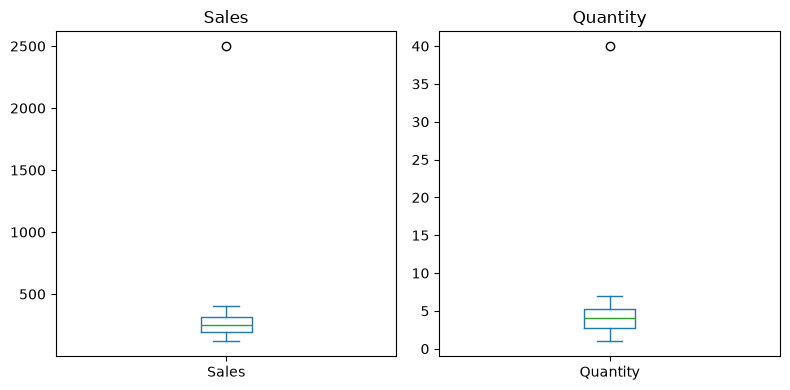

Original Data:
         Sales  Quantity
mean    433.33      6.83
median  250.00      4.00
std     655.78     10.59

Filtered Data:
         Sales  Quantity
mean    245.45      3.82
median  240.00      4.00
std      84.30      1.83

Filtered Dataset:
    Transaction_ID  Sales  Quantity
0                1    120         1
1                2    150         2
2                3    180         2
3                4    200         3
4                5    220         3
5                6    240         4
6                7    260         4
7                8    280         5
8                9    300         5
9               10    350         6
10              11    400         7


In [2]:

import matplotlib.pyplot as plt

# Boxplots
df[["Sales", "Quantity"]].plot(
    kind="box", subplots=True, layout=(1,2),
    figsize=(8,4), title=["Sales", "Quantity"]
)
plt.tight_layout()
plt.show()

# Filter outliers from both columns
filtered = df[
    ~(result["Sales_Outlier"] | result["Quantity_Outlier"])
]

# Compare statistics
print("Original Data:")
print(df[["Sales", "Quantity"]].agg(
    ["mean", "median", "std"]
).round(2))

print("\nFiltered Data:")
print(filtered[["Sales", "Quantity"]].agg(
    ["mean", "median", "std"]
).round(2))

print("\nFiltered Dataset:")
print(filtered)


Question 2: Z-Score Detection and Statistical Interpretation

A. Calculate Z-scores and identify outliers

    Machine_ID  Temperature  Pressure  Temperature_Z  Temperature_Outlier  \
0            1           68        30          -0.52                False   
1            2           70        32          -0.36                False   
2            3           69        31          -0.44                False   
3            4           72        33          -0.20                False   
4            5           71        32          -0.28                False   
5            6           73        34          -0.11                False   
6            7           70        31          -0.36                False   
7            8           74        33          -0.03                False   
8            9           68        32          -0.52                False   
9           10           72        35          -0.20                False   
10          11           71        34          -0.28                False   
11          12          115        60           3.28                 True   

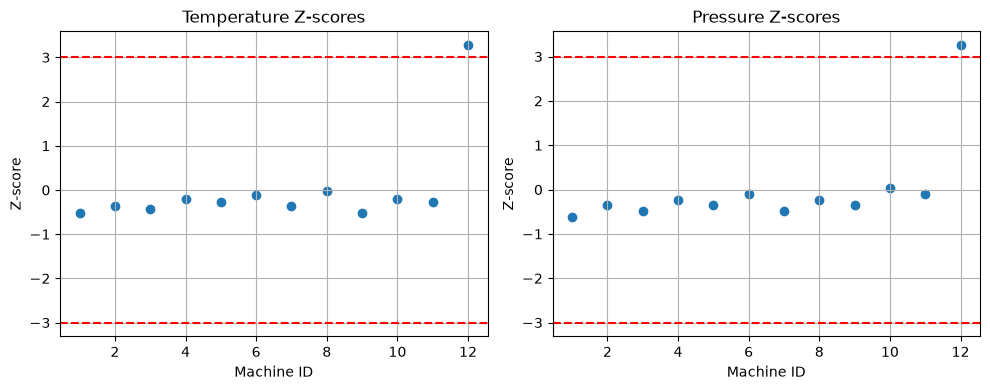

In [3]:

import pandas as pd
import numpy as np
from scipy.stats import zscore
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Machine_ID": range(1, 13),
    "Temperature": [68,70,69,72,71,73,70,74,68,72,71,115],
    "Pressure": [30,32,31,33,32,34,31,33,32,35,34,60]
})

result = df.copy()

for col in ["Temperature", "Pressure"]:
    result[col + "_Z"] = zscore(df[col])
    result[col + "_Outlier"] = result[col + "_Z"].abs() > 3

print(result.round(2))

# Scatterplots of Z-scores
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, ["Temperature", "Pressure"]):
    ax.scatter(df["Machine_ID"], result[col + "_Z"])
    ax.axhline(3, color="red", linestyle="--")
    ax.axhline(-3, color="red", linestyle="--")
    ax.set_title(col + " Z-scores")
    ax.set_xlabel("Machine ID")
    ax.set_ylabel("Z-score")
    ax.grid(True)

plt.tight_layout()
plt.show()


B. Compare thresholds 2 and 3

In [4]:

for col in ["Temperature", "Pressure"]:
    z = zscore(df[col])

    for threshold in [2, 3]:
        outliers = df.loc[abs(z) > threshold, "Machine_ID"]
        print(col, "Threshold:", threshold,
              "Count:", len(outliers),
              "Machines:", outliers.tolist())


Temperature Threshold: 2 Count: 1 Machines: [12]
Temperature Threshold: 3 Count: 1 Machines: [12]
Pressure Threshold: 2 Count: 1 Machines: [12]
Pressure Threshold: 3 Count: 1 Machines: [12]


Question 3: Comparing IQR and Z-Score on Skewed Data

A. Detect outliers using IQR and Z-score

In [5]:

import pandas as pd
import numpy as np
from scipy.stats import zscore

df = pd.DataFrame({
    "Transaction_Amount": [
        100,120,130,150,160,170,180,200,220,
        250,300,350,400,450,500,800,1200,10000
    ]
})

# IQR calculation
q1 = df["Transaction_Amount"].quantile(0.25)
q3 = df["Transaction_Amount"].quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr

# Outlier detection
df["Z_Score"] = zscore(df["Transaction_Amount"])
df["IQR_Flag"] = (
    (df["Transaction_Amount"] < low) |
    (df["Transaction_Amount"] > high)
)
df["Z_Flag"] = df["Z_Score"].abs() > 3

print("Q1:", q1, "Q3:", q3, "IQR:", iqr)
print("Lower:", low, "Upper:", high)
print(df.round(2))

print("\nIQR Outliers:")
print(df[df["IQR_Flag"]])

print("\nZ-score Outliers:")
print(df[df["Z_Flag"]])


Q1: 162.5 Q3: 437.5 IQR: 275.0
Lower: -250.0 Upper: 850.0
    Transaction_Amount  Z_Score  IQR_Flag  Z_Flag
0                  100    -0.35     False   False
1                  120    -0.34     False   False
2                  130    -0.33     False   False
3                  150    -0.32     False   False
4                  160    -0.32     False   False
5                  170    -0.31     False   False
6                  180    -0.31     False   False
7                  200    -0.30     False   False
8                  220    -0.29     False   False
9                  250    -0.28     False   False
10                 300    -0.26     False   False
11                 350    -0.23     False   False
12                 400    -0.21     False   False
13                 450    -0.19     False   False
14                 500    -0.17     False   False
15                 800    -0.03     False   False
16                1200     0.15      True   False
17               10000     4.09      True 

B. Plot distribution and boxplot

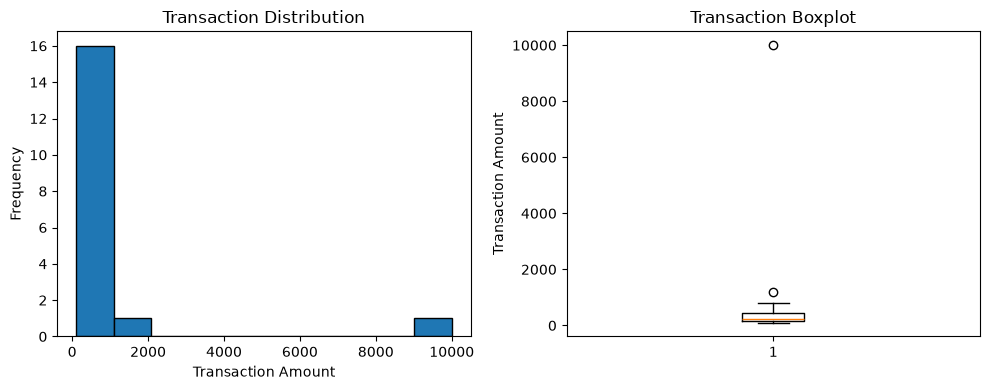

In [6]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Original distribution
ax[0].hist(df["Transaction_Amount"], bins=10, edgecolor="black")
ax[0].set_title("Transaction Distribution")
ax[0].set_xlabel("Transaction Amount")
ax[0].set_ylabel("Frequency")

# Boxplot
ax[1].boxplot(df["Transaction_Amount"])
ax[1].set_title("Transaction Boxplot")
ax[1].set_ylabel("Transaction Amount")

plt.tight_layout()
plt.show()


Question 4: Outlier Detection in Student Performance

A. Apply IQR and Z-score methods

Study_Hours Q1: 2.75 Q3: 5.25 IQR: 2.5 Bounds: -1.0 9.0
Exam_Score Q1: 47.25 Q3: 69.0 IQR: 21.75 Bounds: 14.625 101.625

Outlier Results:
    Student_ID  Study_Hours  Exam_Score  Study_Hours_IQR  Study_Hours_Z  \
0            1            1          35            False          False   
1            2            2          40            False          False   
2            3            2          45            False          False   
3            4            3          48            False          False   
4            5            3          52            False          False   
5            6            4          55            False          False   
6            7            4          60            False          False   
7            8            5          65            False          False   
8            9            5          68            False          False   
9           10            6          72            False          False   
10          11            7          

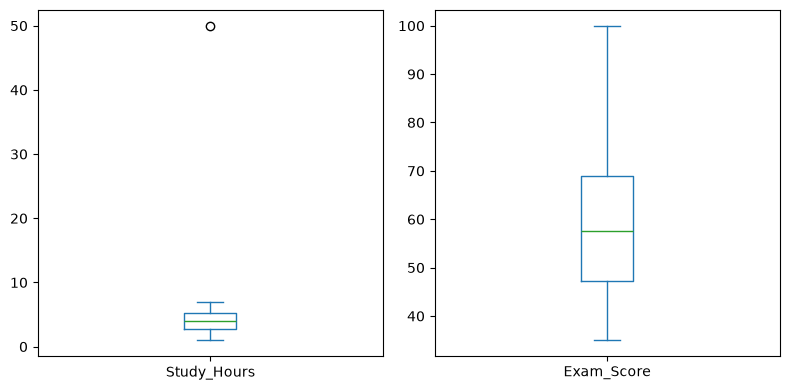

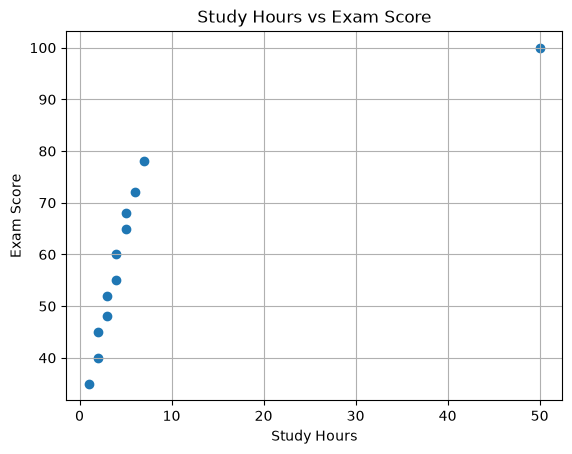

In [7]:

import pandas as pd
import numpy as np
from scipy.stats import zscore
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Student_ID": range(1, 13),
    "Study_Hours": [1,2,2,3,3,4,4,5,5,6,7,50],
    "Exam_Score": [35,40,45,48,52,55,60,65,68,72,78,100]
})

result = df.copy()

for col in ["Study_Hours", "Exam_Score"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr

    result[col + "_IQR"] = (
        (df[col] < low) | (df[col] > high)
    )
    result[col + "_Z"] = abs(zscore(df[col])) > 3

    print(col, "Q1:", q1, "Q3:", q3,
          "IQR:", iqr, "Bounds:", low, high)

print("\nOutlier Results:")
print(result)

# Boxplots
df[["Study_Hours", "Exam_Score"]].plot(
    kind="box", subplots=True, layout=(1,2),
    figsize=(8,4)
)
plt.tight_layout()
plt.show()

# Scatterplot
plt.scatter(df["Study_Hours"], df["Exam_Score"])
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Score")
plt.grid()
plt.show()


B. Correlation before and after removing outliers

In [8]:

# Original correlation
corr1 = df["Study_Hours"].corr(df["Exam_Score"])

# Remove records flagged by any method
flags = result[[
    "Study_Hours_IQR", "Study_Hours_Z",
    "Exam_Score_IQR", "Exam_Score_Z"
]].any(axis=1)

filtered = df[~flags]

# Filtered correlation
corr2 = filtered["Study_Hours"].corr(
    filtered["Exam_Score"]
)

print("Original Correlation:", round(corr1, 4))
print("Filtered Correlation:", round(corr2, 4))
print("Removed Students:", df.loc[flags, "Student_ID"].tolist())


Original Correlation: 0.7818
Filtered Correlation: 0.9877
Removed Students: [12]
